Ground Truth test

In [25]:
lifecyclesavings.shape

(50, 7)

In [26]:
import pandas as pd
lifecyclesavings = pd.read_csv("/lifecyclesavings.csv")
lifecyclesavings.head()

,Contry,sr,pop15,pop75,dpi,ddpi
0,Australia,11.43,29.35,2.87,2329.68,2.87
1,Austria,12.07,23.32,4.41,1507.99,3.93
2,Belgium,13.17,23.80,4.43,2108.47,3.82
3,Bolivia,5.75,41.89,1.67,189.13,0.22
4,Brazil,12.88,42.19,0.83,728.47,4.56


In [27]:
lifecyclesavings.isna().sum()

,0
Contry,0
sr,0
pop15,0
pop75,0
dpi,0
ddpi,0


In [28]:
lifecyclesavings[["sr","pop15","pop75","dpi","ddpi"]].mean()

,0
sr,9.6710
pop15,35.0896
pop75,2.2930
dpi,1106.7584
ddpi,3.7576


AI Assisted test:

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Select the numerical features related to savings behavior
features = ['sr', 'pop15', 'pop75', 'dpi', 'ddpi']
X = lifecyclesavings[features]

# 2. Standardize the features (K-Means is sensitive to differences in variance/scales)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Fit K-Means clustering (let's use 3 clusters as a starting point)
kmeans = KMeans(n_clusters=3, random_state=42)
lifecyclesavings['cluster'] = kmeans.fit_predict(X_scaled)

# 4. Convert cluster column to categorical string for better visualization legends
lifecyclesavings['cluster'] = lifecyclesavings['cluster'].astype(str)

# Display the dataset with the assigned cluster labels
display(lifecyclesavings.head())


,Contry,sr,pop15,pop75,dpi,ddpi,cluster
0,Australia,11.43,29.35,2.87,2329.68,2.87,2
1,Austria,12.07,23.32,4.41,1507.99,3.93,2
2,Belgium,13.17,23.80,4.43,2108.47,3.82,2
3,Bolivia,5.75,41.89,1.67,189.13,0.22,0
4,Brazil,12.88,42.19,0.83,728.47,4.56,1


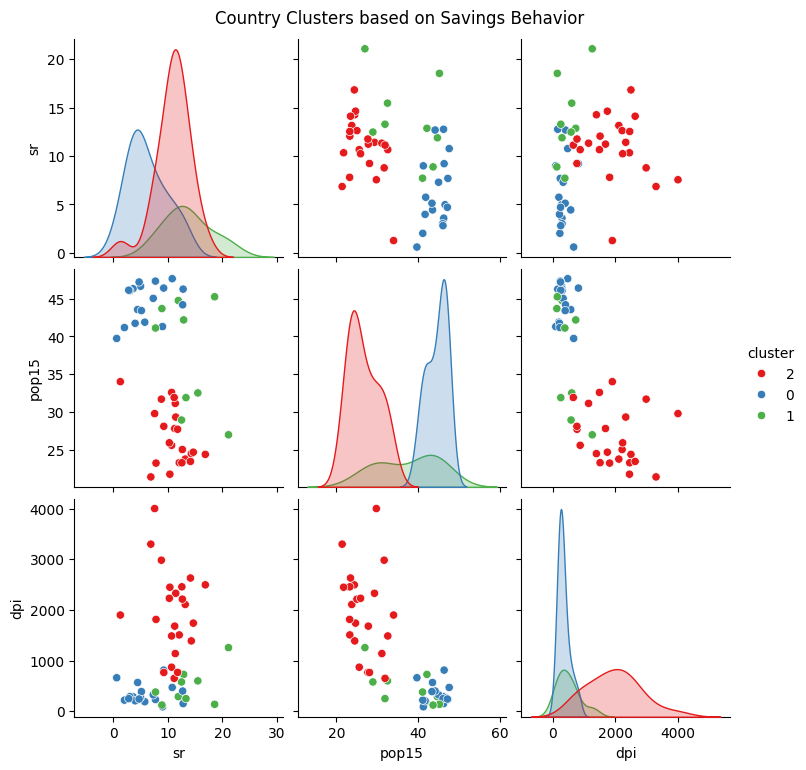

In [30]:
# 5. Visualize the clusters
# We will use a pairplot to see how the clusters distribute across the savings rate (sr), disposable income (dpi), and population demographic columns
sns.pairplot(lifecyclesavings, vars=['sr', 'pop15', 'dpi'], hue='cluster', palette='Set1', diag_kind='kde')
plt.suptitle('Country Clusters based on Savings Behavior', y=1.02)
plt.show()


In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Create a copy of the original dataset to protect it from modifications
clustered_data = lifecyclesavings.copy()

# 1. Select the numerical features related to savings behavior
features = ['sr', 'pop15', 'pop75', 'dpi', 'ddpi']
X = clustered_data[features]

# 2. Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Fit K-Means clustering with 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42)
clustered_data['cluster'] = kmeans.fit_predict(X_scaled)
clustered_data['cluster'] = clustered_data['cluster'].astype(str)


In [32]:
# 4. Display the number of countries in each cluster
print("Number of countries in each cluster:")
display(clustered_data['cluster'].value_counts())

# 5. Display the mean of key metrics for each cluster
print("\nMean values of features for each cluster:")
cluster_means = clustered_data.groupby('cluster')[features].mean()
display(cluster_means)


Number of countries in each cluster:


,count
cluster,
2,23
0,18
1,9



Mean values of features for each cluster:


,sr,pop15,pop75,dpi,ddpi
cluster,,,,,
0,6.138889,44.556111,1.079444,337.153333,2.359444
1,13.591111,37.492222,1.623333,483.241111,7.662222
2,10.901304,26.740870,3.504783,1953.043043,3.323913


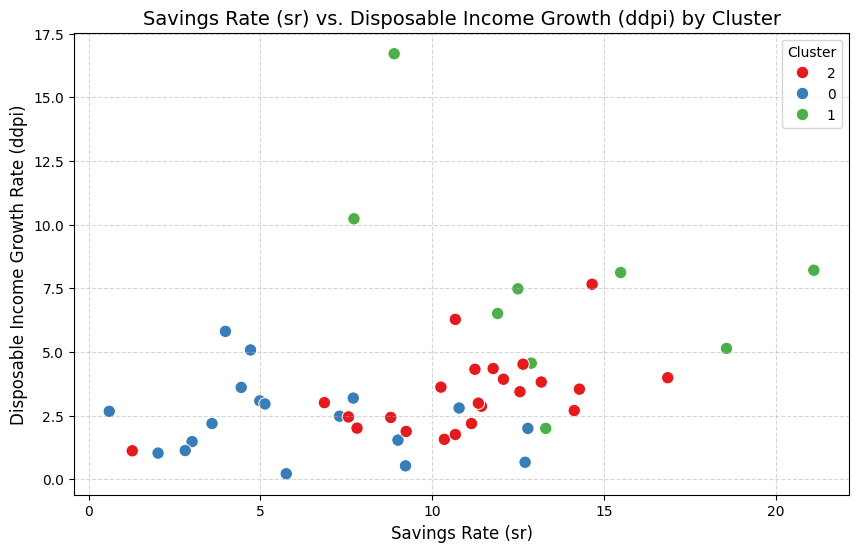

In [33]:
# 6. Create a single labeled scatterplot of sr versus ddpi, colored by cluster
plt.figure(figsize=(10, 6))
sns.scatterplot(data=clustered_data, x='sr', y='ddpi', hue='cluster', palette='Set1', s=80)

# Adding labels and title
plt.title('Savings Rate (sr) vs. Disposable Income Growth (ddpi) by Cluster', fontsize=14)
plt.xlabel('Savings Rate (sr)', fontsize=12)
plt.ylabel('Disposable Income Growth Rate (ddpi)', fontsize=12)
plt.legend(title='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


In [34]:
clustered_data.groupby("cluster")[["sr", "pop15", "pop75", "dpi", "ddpi"]].mean().loc["0"]

,0
sr,6.138889
pop15,44.556111
pop75,1.079444
dpi,337.153333
ddpi,2.359444


The cluster seems to represent how countries compare based on their savings. I verfied Gemini's output by running my own groupby calculation for cluster 0. the results I ran matched the AI output. One caution is when not familiar with the data is not being able to catch if the intrepretation is incorrect or leaving out data. Also not being familar with the expected output is also a caution as it may create a different chart or table. Someone needs to be able to verfiy the outputs accurratly.

AI Prompt Log: Gemini
first prompt: You are helping with exploratory data analysis. My CSV has columns: Country, sr, pop15, pop75, dpi, and ddpi. Write Python using pandas and seaborn to: help me cluster the countries into groups by their savings behavior and visualize the result. Explain each step in comments
Result: returned clustering but it modified the orginal dataframe.

second prompt: Please correct the code. The previous version modified my original lifecyclesavings DataFrame and did not follow the requested output. Create clustered_data = lifecyclesavings.copy() and add the cluster labels only to clustered_data. Display the number of countries in each cluster and the mean of sr, pop15, pop75, dpi, and ddpi for each cluster. Replace the pairplot with one labeled scatterplot of sr versus ddpi, colored by cluster. Keep the StandardScaler and KMeans with 3 clusters and random_state=42.
result: corrected the code and created the correct chart

CHAT GPT USE:
Helped me format the second prompt to correct the code, which really helped me see how detailed to be in the prompt.

https://github.com/e-flores-data/cs82a-portfolio